# Natural-gas prices and storage-contract valuation

Four years of month-end prices (Oct 2020 to Sep 2024). Goal: estimate the price on any date, extrapolate a year ahead, and value a storage contract.

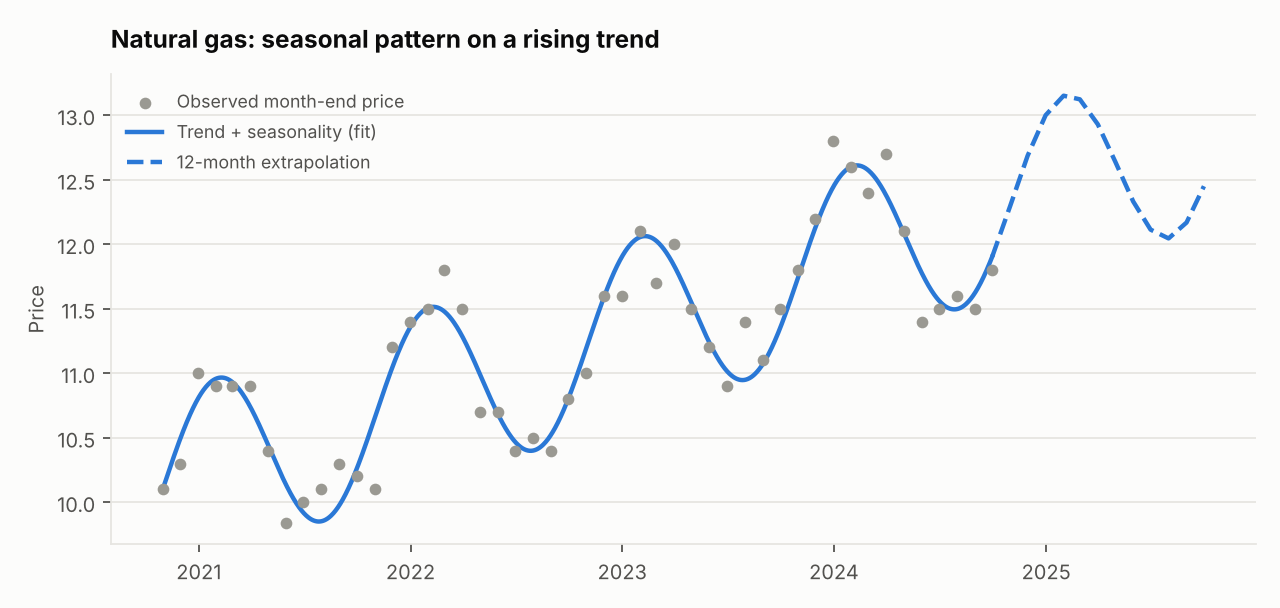

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from quant_research import *
from quant_research import viz
pd.set_option('display.width', 120)
prices = load_gas_prices()
model = GasPriceModel(harmonics=1).fit(prices)
viz.gas_curve(prices, model, '../docs/gas_curve.png')
from IPython.display import Image; Image('../docs/gas_curve.png')

## Does the seasonal model earn its complexity?

Hold out the last 12 months, fit on the first 36, compare with simple baselines. With only 48 observations this is indicative, not conclusive.

In [2]:
from quant_research.gas_pricing import backtest
bt = backtest(prices)
viz.backtest_bars(bt, '../docs/gas_backtest.png')
bt

,model,MAE,RMSE,MAPE_%
0,last value carried forward,0.550,0.719,4.426
1,same month last year,0.567,0.627,4.656
2,linear trend only,0.541,0.625,4.414
3,trend + annual seasonality,0.160,0.208,1.327


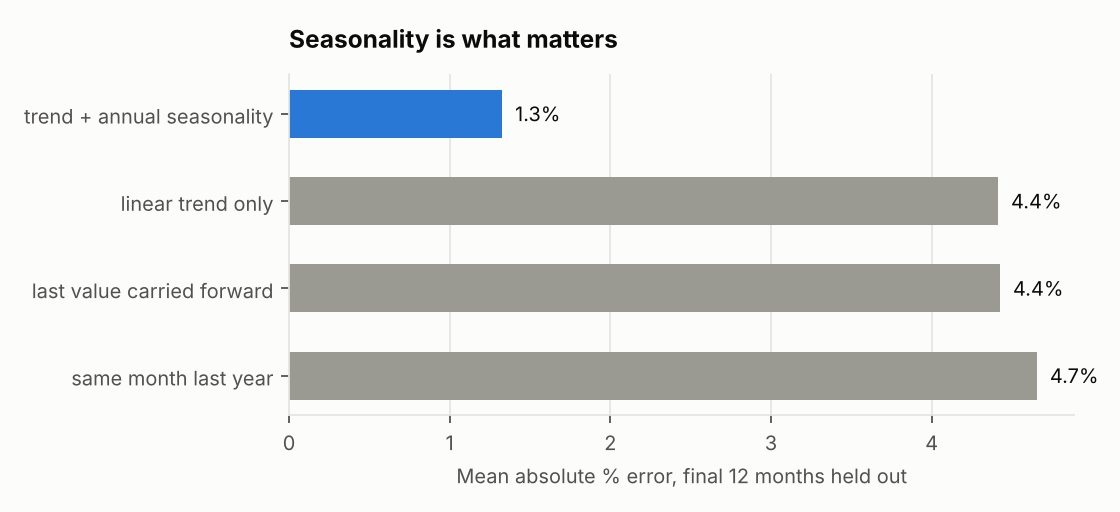

In [3]:
Image('../docs/gas_backtest.png')

The earlier version used a straight-line fit; it misses the winter/summer cycle, and trend alone is no better than carrying the last price forward. Adding one annual harmonic cuts the error by roughly two thirds.

## Pricing a storage contract

Buy in summer, sell in winter. `price_storage_contract` values the plan as **sales - purchases - storage rent - fees**, rejects physically impossible plans (overfilling, selling gas you do not hold, breaching rate limits), and charges rent on the inventory actually held.

In [4]:
cv = price_storage_contract(
    model.price,
    injections={'2024-06-30': 1000, '2024-07-31': 1000},
    withdrawals={'2024-12-31': 1000, '2025-01-31': 1000},
    max_volume=2000, injection_rate=1000, withdrawal_rate=1000,
    storage_cost_per_unit_day=0.002, injection_fee_per_unit=0.01, withdrawal_fee_per_unit=0.01)
print(f'value ${cv.value:,.0f} = revenue ${cv.revenue:,.0f} - purchases ${cv.purchase_cost:,.0f} '
      f'- storage ${cv.storage_cost:,.0f} - fees ${cv.fees:,.0f}')
pd.DataFrame(cv.schedule)

value $2,277 = revenue $26,153 - purchases $23,100 - storage $736 - fees $40


,date,volume,price,inventory
0,2024-06-30,1000,11.5000,1000.0
1,2024-07-31,1000,11.6000,2000.0
2,2024-12-31,-1000,13.0008,1000.0
3,2025-01-31,-1000,13.1523,0.0


In [5]:
# Same idea, wrong season: buying in winter and selling in summer destroys value.
bad = price_storage_contract(model.price, {'2024-01-31': 1000}, {'2024-07-31': 1000}, max_volume=1000,
    injection_rate=1000, withdrawal_rate=1000, storage_cost_per_unit_day=0.002)
print(f'value ${bad.value:,.0f}')

value $-1,364
